In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.metrics import mean_absolute_error, mean_squared_error

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [4]:
df = pd.read_csv("../data/processed/sales_features.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values(
    ["date", "store", "item"]
).reset_index(drop=True)

print("Dataset shape:", df.shape)

Dataset shape: (899000, 17)


In [ ]:
# Define predictors and target
features = [
    "store", "item",
    "year", "month", "day", "day_of_week",
    "week_of_year", "quarter", "is_weekend",
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

target = "sales"

In [ ]:
# Chronological split
train = df[df["date"] <= "2016-12-31"]

validation = df[
    (df["date"] >= "2017-01-01") &
    (df["date"] <= "2017-06-30")
]

test = df[
    (df["date"] >= "2017-07-01") &
    (df["date"] <= "2017-12-31")
]

X_train = train[features]
y_train = train[target]

X_val = validation[features]
y_val = validation[target]

X_test = test[features]
y_test = test[target]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (716500, 15)
Validation: (90500, 15)
Testing: (92000, 15)


In [ ]:
# Train XGBoost
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

print("XGBoost training completed.")

[0]	validation_0-mae:23.22366
[50]	validation_0-mae:6.38992
[100]	validation_0-mae:6.00805
[150]	validation_0-mae:5.97217
[200]	validation_0-mae:5.95679
[250]	validation_0-mae:5.94986
[300]	validation_0-mae:5.94414
[350]	validation_0-mae:5.94177
[400]	validation_0-mae:5.93955
[450]	validation_0-mae:5.93780
[499]	validation_0-mae:5.93742
XGBoost training completed.


In [ ]:
# Evaluate XGBoost
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted)) /
        np.sum(np.abs(actual))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    }


val_predictions = xgb_model.predict(X_val)
test_predictions = xgb_model.predict(X_test)

print("Validation Results:")
print(evaluate_model(y_val, val_predictions))

print("\nTest Results:")
print(evaluate_model(y_test, test_predictions))

Validation Results:
{'MAE': 5.937418460845947, 'RMSE': np.float64(7.7218194333543), 'WAPE': np.float64(10.566018767618617)}

Test Results:
{'MAE': 6.260879039764404, 'RMSE': np.float64(8.129999588594508), 'WAPE': np.float64(10.19790763188867)}


In [ ]:
# Save the model
os.makedirs("../models", exist_ok=True)

joblib.dump(
    xgb_model,
    "../models/xgboost_model.pkl"
)

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


            Feature  Importance
13   rolling_mean_7    0.484019
10            lag_7    0.210261
14  rolling_mean_28    0.096236
8        is_weekend    0.065473
11           lag_14    0.052306
5       day_of_week    0.042422
9             lag_1    0.014098
3             month    0.009829
7           quarter    0.006754
12           lag_28    0.006539
6      week_of_year    0.005491
4               day    0.003810
2              year    0.001027
0             store    0.000877
1              item    0.000860


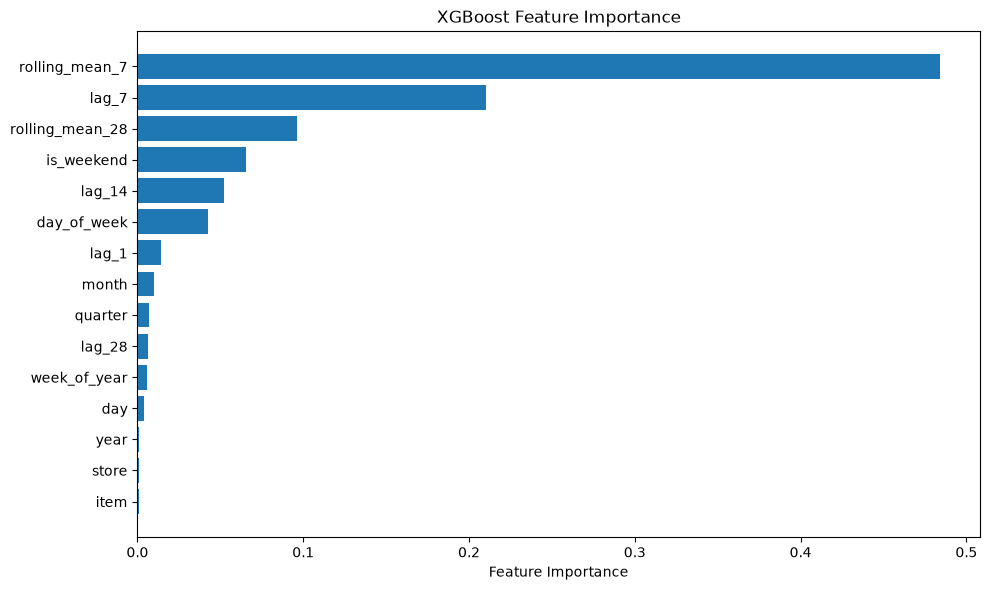

In [ ]:
# Feature importance
importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

os.makedirs("../reports", exist_ok=True)

importance.to_csv(
    "../reports/xgboost_feature_importance.csv",
    index=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# final XGBoost test predictions
test_results = test[
    ["date", "store", "item", "sales"]
].copy()

test_results = test_results.rename(
    columns={"sales": "actual_sales"}
)

test_results["predicted_sales"] = test_predictions

test_results.to_csv(
    "../reports/xgboost_test_predictions.csv",
    index=False
)

print(test_results.head())
print("Predictions saved.")

             date  store  item  actual_sales  predicted_sales
807000 2017-07-01      1     1            31        33.887970
807001 2017-07-01      1     2            83        86.111389
807002 2017-07-01      1     3            41        52.265232
807003 2017-07-01      1     4            37        32.862923
807004 2017-07-01      1     5            26        26.239096
Predictions saved.


In [ ]:

joblib.dump(
    xgb_model,
    "../models/xgboost_model.pkl"
)

importance.to_csv(
    "../reports/xgboost_feature_importance.csv",
    index=False
)